<a href="https://colab.research.google.com/github/adithya-ashoks/deep-learning-practice/blob/main/perceptron_and_xor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


In [12]:
# XOR dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 0])

In [13]:
# 1. Single-layer perceptron
single_layer = Perceptron(
    max_iter=1000,
    eta0=0.1,
    tol=None,
    random_state=42
)
single_layer.fit(X, y)

single_predictions = single_layer.predict(X)

In [14]:
# 2. Multilayer perceptron
multi_layer = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation='tanh',
    solver='lbfgs',
    max_iter=5000,
    random_state=42
)

multi_layer.fit(X, y)

multi_predictions = multi_layer.predict(X)


In [15]:
# Display predictions
print("XOR Dataset:")
print("Input\tActual\tSingle Layer\tMulti Layer")

for i in range(len(X)):
    print(
        f"{X[i]}\t{y[i]}\t"
        f"{single_predictions[i]}\t\t{multi_predictions[i]}"
    )

print("\nSingle Layer Accuracy:",
      accuracy_score(y, single_predictions) * 100, "%")

print("Multi Layer Accuracy:",
      accuracy_score(y, multi_predictions) * 100, "%")

XOR Dataset:
Input	Actual	Single Layer	Multi Layer
[0 0]	0	0		0
[0 1]	1	0		1
[1 0]	1	0		1
[1 1]	0	0		0

Single Layer Accuracy: 50.0 %
Multi Layer Accuracy: 100.0 %


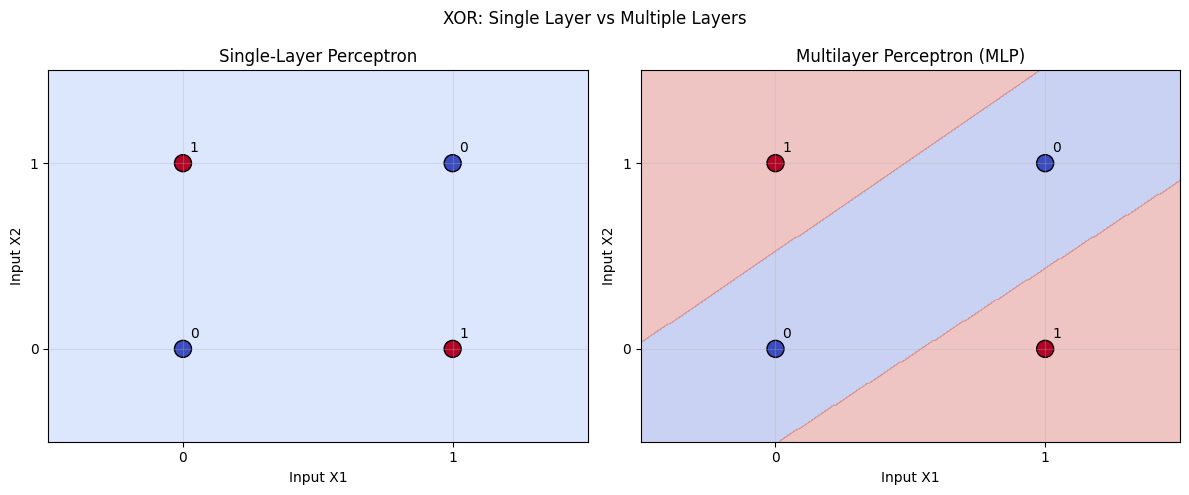

In [16]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Create a grid for decision boundaries
xx, yy = np.meshgrid(
    np.linspace(-0.5, 1.5, 300),
    np.linspace(-0.5, 1.5, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

models = [
    (single_layer, "Single-Layer Perceptron"),
    (multi_layer, "Multilayer Perceptron (MLP)")
]

for ax, (model, title) in zip(axes, models):

    predictions = model.predict(grid)
    predictions = predictions.reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        alpha=0.3,
        cmap='coolwarm'
    )

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap='coolwarm',
        edgecolors='black',
        s=150
    )

    for i, point in enumerate(X):
        ax.annotate(
            str(y[i]),
            (point[0], point[1]),
            xytext=(5, 8),
            textcoords='offset points'
        )

    ax.set_title(title)
    ax.set_xlabel("Input X1")
    ax.set_ylabel("Input X2")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.grid(alpha=0.3)

plt.suptitle("XOR: Single Layer vs Multiple Layers")
plt.tight_layout()
plt.show()
